<a href="https://colab.research.google.com/github/aribarahmanii/Breasttumor/blob/main/ca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# BUSI breast ultrasound lesion segmentation
# Tier 1: Attention U-Net | Tier 2: D-SAS | Tier 3: CA-BSNet (proposed)
# ------------------------------------------------------------
# RULES FOR THIS NOTEBOOK
# 1. The train/val/test split is created once, then frozen (never regenerated).
# 2. Models are trained once; the training cells are kept as Text and not re-run.
# 3. Every reported number comes from the final evaluation cells,
#    which load the saved checkpoints from Drive.
# Dataset: BUSI, deduplicated (527 images), split 368 / 78 / 81
# ============================================================


from google.colab import drive
drive.mount('/content/drive')
import shutil, os
FINAL_DIR = '/content/drive/MyDrive/BUSI_Dataset'
BK = '/content/drive/MyDrive/BUSI_FROZEN_BACKUP'; os.makedirs(BK, exist_ok=True)
for f in ['train.csv', 'val.csv', 'test.csv']:
    shutil.copy2(f'{FINAL_DIR}/{f}', BK)
for t in ['tier1_attention_unet', 'tier2_dsas', 'tier3_cabsnet']:
    shutil.copytree(f'{FINAL_DIR}/{t}/checkpoints', f'{BK}/{t}_ckpt', dirs_exist_ok=True)
print('Backup done ->', BK, os.listdir(BK))

In [ ]:
# CELL 1 - SETUP: mounts Drive, imports libraries, picks GPU/CPU, sets seed 42, and defines paths and constants (RAW_ROOT, CLASSES, IMG_SIZE, FINAL_DIR, PROJECT_DIR).
from google.colab import drive
drive.mount('/content/drive')

import os, time, csv, json, hashlib, random
from collections import defaultdict
from itertools import combinations

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from scipy.ndimage import distance_transform_edt, binary_erosion

print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
random.seed(42)

RAW_ROOT = '/content/data/Dataset_BUSI_with_GT'
CLASSES = ['benign', 'malignant']
NEAR_DUP_THRESHOLD = 5
IMG_SIZE = 256
FINAL_DIR = '/content/drive/MyDrive/BUSI_Dataset'
PROJECT_DIR = f'{FINAL_DIR}/tier1_attention_unet'
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/logs', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA available: True
Using device: cuda


In [ ]:
# CELL 2 - DATASET DOWNLOAD CHECK: downloads BUSI from Kaggle only if it is not already in this session.
if not os.path.exists(RAW_ROOT):
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    os.makedirs("/content/data", exist_ok=True)
    os.system("pip install -q -U kaggle")
    os.system(
        "kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset "
        "-p /content/data --unzip"
    )
print("Raw dataset present:", os.path.exists(RAW_ROOT))


Raw dataset present: True


In [ ]:
# CELL 3 - DEDUPLICATION: finds exact (MD5) and near-duplicate (pHash) images, drops cross-class conflicts,
# keeps one image per same-class group -> kept_records (527 images). Skipped if the frozen split already exists.
try:
    import imagehash
except ImportError:
    os.system("pip install -q ImageHash")
    import imagehash

def collect_images(root, classes):
    records = []
    for cls in classes:
        folder = os.path.join(root, cls)
        all_files = sorted(os.listdir(folder))          # sorted -> same order every session
        images = [f for f in all_files
                  if f.lower().endswith(('.png', '.jpg', '.jpeg')) and '_mask' not in f.lower()]
        for image_file in images:
            base_name = os.path.splitext(image_file)[0]
            masks = [f for f in all_files if f.startswith(base_name + '_mask')]
            records.append({
                'class': cls, 'filename': image_file,
                'image_path': os.path.join(folder, image_file),
                'mask_paths': [os.path.join(folder, m) for m in masks],
            })
    return records

def md5_hash(filepath):
    md5 = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            md5.update(chunk)
    return md5.hexdigest()

def phash(filepath):
    return imagehash.phash(Image.open(filepath).convert('L'))

def find_exact_duplicate_groups(records):
    groups = defaultdict(list)
    for r in records:
        groups[md5_hash(r['image_path'])].append(r)
    return [g for g in groups.values() if len(g) > 1]

def find_near_duplicate_pairs(records, threshold):
    hashes = [(r, phash(r['image_path'])) for r in records]
    pairs = []
    for (r_a, h_a), (r_b, h_b) in combinations(hashes, 2):
        if h_a - h_b <= threshold:
            pairs.append((r_a, r_b, h_a - h_b))
    return pairs

class UnionFind:
    def __init__(self, items):
        self.parent = {id(item): item for item in items}
    def find(self, item):
        pid = id(item)
        while self.parent[pid] is not item:
            item = self.parent[pid]; pid = id(item)
        return item
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra is not rb:
            self.parent[id(ra)] = rb

def group_near_duplicates(records, pairs):
    uf = UnionFind(records)
    for r_a, r_b, _ in pairs:
        uf.union(r_a, r_b)
    groups = defaultdict(list)
    for r in records:
        groups[id(uf.find(r))].append(r)
    return [g for g in groups.values() if len(g) > 1]

# Is there already a frozen train/val/test split on Drive?
SPLIT_FILES = {k: f'{FINAL_DIR}/{k}.csv' for k in ['train', 'val', 'test']}
SPLIT_EXISTS = all(os.path.exists(p) for p in SPLIT_FILES.values())
print("Frozen split on Drive:", SPLIT_EXISTS)

if not SPLIT_EXISTS:
    print("Collecting image records...")
    records = collect_images(RAW_ROOT, CLASSES)
    print(f"Total benign+malignant images: {len(records)}")

    exact_groups = find_exact_duplicate_groups(records)
    print(f"Exact duplicate groups: {len(exact_groups)}")

    near_pairs = find_near_duplicate_pairs(records, NEAR_DUP_THRESHOLD)
    near_groups = group_near_duplicates(records, near_pairs)
    print(f"Near-duplicate groups: {len(near_groups)}")

    same_class_groups, cross_class_groups = [], []
    for g in near_groups:
        (cross_class_groups if len({r['class'] for r in g}) > 1 else same_class_groups).append(g)
    print(f"Same-class groups: {len(same_class_groups)} | Cross-class conflicts: {len(cross_class_groups)}")

    excluded_paths = {r['image_path'] for g in cross_class_groups for r in g}
    kept_records, seen_paths = [], set()
    for g in same_class_groups:
        kept_records.append(g[0]); seen_paths.add(g[0]['image_path'])
        for r in g[1:]:
            seen_paths.add(r['image_path'])
    for r in records:
        if r['image_path'] not in excluded_paths and r['image_path'] not in seen_paths:
            kept_records.append(r)

    print(f"\nFinal deduplicated dataset: {len(kept_records)} images (removed {len(records) - len(kept_records)})")
    for cls in CLASSES:
        n = sum(1 for r in kept_records if r['class'] == cls)
        print(f"  {cls}: {n}")

Frozen split on Drive: True


In [ ]:
# CELL 4 - TRAIN/VAL/TEST SPLIT: stratified 70/15/15 split, saved to Drive as train/val/test.csv.
# If the CSVs already exist, they are FROZEN and left untouched, so every model is evaluated on the same test set.
def stratified_split(records, classes, ratios=(0.70, 0.15, 0.15), seed=42):
    rng = random.Random(seed)          # private generator, unaffected by any other code
    train, val, test = [], [], []
    for cls in classes:
        cls_records = sorted([r for r in records if r['class'] == cls], key=lambda r: r['filename'])
        rng.shuffle(cls_records)
        n = len(cls_records)
        n_train, n_val = int(n * ratios[0]), int(n * ratios[1])
        train += cls_records[:n_train]
        val   += cls_records[n_train:n_train + n_val]
        test  += cls_records[n_train + n_val:]
    return train, val, test

def save_split_csv(path, records):
    with open(path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['class', 'image_path', 'mask_paths'])
        for r in records:
            writer.writerow([r['class'], r['image_path'], '|'.join(r['mask_paths'])])

if SPLIT_EXISTS:
    print("FROZEN SPLIT FOUND - train/val/test.csv left untouched")
else:
    train_records, val_records, test_records = stratified_split(kept_records, CLASSES)
    print(f"Split - train: {len(train_records)}, val: {len(val_records)}, test: {len(test_records)}")
    for k, recs in zip(['train', 'val', 'test'], [train_records, val_records, test_records]):
        save_split_csv(SPLIT_FILES[k], recs)
    print(f"NEW SPLIT CREATED in {FINAL_DIR} - every model must be retrained")

FROZEN SPLIT FOUND - train/val/test.csv left untouched


In [ ]:
# CELL 5 - DATA PIPELINE: transforms (augmentation for train only), dataset class that reads the frozen CSVs, and train/val/test loaders.
def get_train_transform(img_size=IMG_SIZE):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=15, p=0.5),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

def get_eval_transform(img_size=IMG_SIZE):
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

class BUSISegmentationDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.records = []
        with open(csv_path, newline='') as f:
            reader = csv.DictReader(f)
            for row in reader:
                mask_paths = row['mask_paths'].split('|') if row['mask_paths'] else []
                self.records.append({'class': row['class'], 'image_path': row['image_path'], 'mask_paths': mask_paths})
        self.transform = transform
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        record = self.records[idx]
        image = np.array(Image.open(record['image_path']).convert('RGB'))
        mask = None
        for mp in record['mask_paths']:
            m = (np.array(Image.open(mp).convert('L')) > 0).astype(np.uint8)
            mask = m if mask is None else np.maximum(mask, m)
        if mask is None:
            mask = np.zeros(image.shape[:2], dtype=np.uint8)
        if self.transform:
            aug = self.transform(image=image, mask=mask)
            image, mask = aug['image'], aug['mask'].unsqueeze(0).float()
        return {'image': image, 'mask': mask, 'class': record['class']}

def get_dataloaders(splits_dir, batch_size=16, img_size=IMG_SIZE, num_workers=2):
    train_ds = BUSISegmentationDataset(f'{splits_dir}/train.csv', transform=get_train_transform(img_size))
    val_ds = BUSISegmentationDataset(f'{splits_dir}/val.csv', transform=get_eval_transform(img_size))
    test_ds = BUSISegmentationDataset(f'{splits_dir}/test.csv', transform=get_eval_transform(img_size))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = get_dataloaders(FINAL_DIR)
_batch = next(iter(train_loader))
print("Sanity check — Image shape:", _batch["image"].shape, "| Mask shape:", _batch["mask"].shape)

Train: 368 | Val: 78 | Test: 81
Sanity check — Image shape: torch.Size([16, 3, 256, 256]) | Mask shape: torch.Size([16, 1, 256, 256])


In [ ]:
# CELL 6 - TIER 1 MODEL: Attention U-Net (encoder-decoder with attention gates on the skip connections). Architecture must not change - saved checkpoints depend on it.
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        psi = self.relu(self.W_g(g) + self.W_x(x))
        return x * self.psi(psi)

class AttentionUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, features=(64, 128, 256, 512)):
        super().__init__()
        self.pool = nn.MaxPool2d(2, 2)
        self.enc1 = ConvBlock(in_ch, features[0])
        self.enc2 = ConvBlock(features[0], features[1])
        self.enc3 = ConvBlock(features[1], features[2])
        self.enc4 = ConvBlock(features[2], features[3])
        self.bottleneck = ConvBlock(features[3], features[3] * 2)
        self.up4 = nn.ConvTranspose2d(features[3] * 2, features[3], 2, stride=2)
        self.att4 = AttentionGate(features[3], features[3], features[3] // 2)
        self.dec4 = ConvBlock(features[3] * 2, features[3])
        self.up3 = nn.ConvTranspose2d(features[3], features[2], 2, stride=2)
        self.att3 = AttentionGate(features[2], features[2], features[2] // 2)
        self.dec3 = ConvBlock(features[2] * 2, features[2])
        self.up2 = nn.ConvTranspose2d(features[2], features[1], 2, stride=2)
        self.att2 = AttentionGate(features[1], features[1], features[1] // 2)
        self.dec2 = ConvBlock(features[1] * 2, features[1])
        self.up1 = nn.ConvTranspose2d(features[1], features[0], 2, stride=2)
        self.att1 = AttentionGate(features[0], features[0], features[0] // 2)
        self.dec1 = ConvBlock(features[0] * 2, features[0])
        self.final = nn.Conv2d(features[0], out_ch, kernel_size=1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.up4(b); d4 = self.dec4(torch.cat([d4, self.att4(g=d4, x=e4)], dim=1))
        d3 = self.up3(d4); d3 = self.dec3(torch.cat([d3, self.att3(g=d3, x=e3)], dim=1))
        d2 = self.up2(d3); d2 = self.dec2(torch.cat([d2, self.att2(g=d2, x=e2)], dim=1))
        d1 = self.up1(d2); d1 = self.dec1(torch.cat([d1, self.att1(g=d1, x=e1)], dim=1))
        return self.final(d1)

print("Model defined")

Model defined


In [ ]:
# CELL 7 - LOSS, METRICS AND TRAIN/VALIDATE FUNCTIONS.
# DiceBCELoss = training loss | compute_metrics = Dice/IoU/Precision/Recall/Specificity/Accuracy | compute_hd95_single = boundary error.
# NOTE: validate() averages over batches and is used ONLY to pick the best epoch while training.
# It is never used for reported results (those come from per-image evaluation in the final cells).
class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred_logits, target):
        bce_loss = self.bce(pred_logits, target)
        pred = torch.sigmoid(pred_logits)
        pf, tf = pred.view(-1), target.view(-1)
        intersection = (pf * tf).sum()
        dice_loss = 1 - (2 * intersection + self.smooth) / (pf.sum() + tf.sum() + self.smooth)
        return bce_loss + dice_loss

def compute_metrics(pred_logits, target, threshold=0.5):
    pred = (torch.sigmoid(pred_logits) > threshold).float()
    tp = (pred * target).sum(); fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum(); tn = ((1 - pred) * (1 - target)).sum()
    dice = (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)
    iou = (tp + 1e-6) / (tp + fp + fn + 1e-6)
    precision = (tp + 1e-6) / (tp + fp + 1e-6)
    recall = (tp + 1e-6) / (tp + fn + 1e-6)
    specificity = (tn + 1e-6) / (tn + fp + 1e-6)
    accuracy = (tp + tn + 1e-6) / (tp + tn + fp + fn + 1e-6)
    return {"dice": dice.item(), "iou": iou.item(), "precision": precision.item(),
            "recall": recall.item(), "specificity": specificity.item(), "accuracy": accuracy.item()}

def compute_hd95_single(pred_mask, gt_mask):
    if not pred_mask.any() or not gt_mask.any():
        return None
    pred_border = pred_mask ^ binary_erosion(pred_mask)
    gt_border = gt_mask ^ binary_erosion(gt_mask)
    dt_gt = distance_transform_edt(~gt_border)
    dt_pred = distance_transform_edt(~pred_border)
    d_pred_to_gt = dt_gt[pred_border]
    d_gt_to_pred = dt_pred[gt_border]
    return max(np.percentile(d_pred_to_gt, 95), np.percentile(d_gt_to_pred, 95))

def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss = 0
    for batch in loader:
        images, masks = batch["image"].to(device), batch["mask"].to(device)
        optimizer.zero_grad()
        preds = model(images)
        loss = loss_fn(preds, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def validate(model, loader, loss_fn, device):
    model.eval()
    total_loss, all_metrics, hd95_values = 0, [], []
    with torch.no_grad():
        for batch in loader:
            images, masks = batch["image"].to(device), batch["mask"].to(device)
            preds = model(images)
            total_loss += loss_fn(preds, masks).item()
            all_metrics.append(compute_metrics(preds, masks))
            pred_bin = (torch.sigmoid(preds) > 0.5).cpu().numpy().astype(bool)
            gt_bin = masks.cpu().numpy().astype(bool)
            for i in range(pred_bin.shape[0]):
                hd = compute_hd95_single(pred_bin[i, 0], gt_bin[i, 0])
                if hd is not None:
                    hd95_values.append(hd)
    avg = {k: sum(m[k] for m in all_metrics) / len(all_metrics) for k in all_metrics[0]}
    avg['hd95_mean'] = float(np.mean(hd95_values)) if hd95_values else float('nan')
    avg['hd95_median'] = float(np.median(hd95_values)) if hd95_values else float('nan')
    avg['hd95_valid_count'] = len(hd95_values)
    return total_loss / len(loader), avg

print("Loss, metrics, train/validate functions defined")

Loss, metrics, train/validate functions defined


In [ ]:
# CELL 8 - SEED CONTROL: set_seed(seed) fixes Python/NumPy/PyTorch randomness so each training seed (42/43/44) is reproducible.
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("set_seed() defined")

set_seed() defined


#CELL 9 - TIER 1 TRAINING (seed 42) - ARCHIVED, DO NOT RUN. Already trained; running it again overwrites attention_unet_best.pth and changes every result. Kept only as a record of how the model was trained.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

set_seed(42)
model = AttentionUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = DiceBCELoss()

NUM_EPOCHS, PATIENCE = 50, 10
best_val_dice, epochs_no_improve = 0.0, 0
checkpoint_path = f'{PROJECT_DIR}/checkpoints/attention_unet_best.pth'
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
    val_loss, val_metrics = validate(model, val_loader, loss_fn, device)
    history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss, **val_metrics})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f} "
          f"| val_dice: {val_metrics['dice']:.4f} | val_iou: {val_metrics['iou']:.4f} | {time.time()-start:.1f}s")
    if val_metrics['dice'] > best_val_dice:
        best_val_dice, epochs_no_improve = val_metrics['dice'], 0
        torch.save(model.state_dict(), checkpoint_path)
        print("  -> new best, checkpoint saved")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

pd.DataFrame(history).to_csv(f'{PROJECT_DIR}/logs/training_history.csv', index=False)
print(f"\nTraining complete. Best val Dice: {best_val_dice:.4f}")

In [ ]:
# ============================================================
# CELL 13 - TIER 2 (D-SAS) MODEL BUILD, SECTION START
# Cells 14-31 build the D-SAS pieces: ResNet101 backbone, SSBG (boundary branch),
# AAS (multi-scale semantic branch), SFH (fusion head) and the progressive decoder.
# ============================================================

In [ ]:
# CELL 14 - LOAD PRETRAINED RESNET101: ImageNet-pretrained ResNet101, the backbone of D-SAS.
# Cell 15 uses this `resnet` object to inspect feature-map sizes.
import torchvision.models as models

resnet = models.resnet101(weights='IMAGENET1K_V2')
print("ResNet101 loaded | layer4 output channels:", resnet.layer4[-1].conv3.out_channels)

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:01<00:00, 171MB/s]


ResNet101 loaded | layer4 output channels: 2048


In [ ]:
# CELL 15 - FEATURE-SIZE CHECK: passes a dummy image through plain ResNet101 to show each stage's output size (layer4 = 8x8 here; cell 16 dilates it to keep 16x16).
x = torch.randn(1, 3, 256, 256)
x = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
print("after stem:", x.shape)          # expect [1, 64, 64, 64]

x1 = resnet.layer1(x)
print("layer1:", x1.shape)             # expect [1, 256, 64, 64]  <- 1/4 resolution

x2 = resnet.layer2(x1)
print("layer2:", x2.shape)             # expect [1, 512, 32, 32]

x3 = resnet.layer3(x2)
print("layer3:", x3.shape)             # expect [1, 1024, 16, 16]

x4 = resnet.layer4(x3)
print("layer4:", x4.shape)             # expect [1, 2048, 8, 8]

after stem: torch.Size([1, 64, 64, 64])
layer1: torch.Size([1, 256, 64, 64])
layer2: torch.Size([1, 512, 32, 32])
layer3: torch.Size([1, 1024, 16, 16])
layer4: torch.Size([1, 2048, 8, 8])


In [ ]:
# CELL 16 - DILATED LAYER4: changes ResNet101's layer4 stride 2 -> 1 (with dilation 2 on 3x3 convs) so the high-level feature map stays 16x16 instead of 8x8.
def modify_layer4_dilation(resnet):
    for name, module in resnet.layer4.named_modules():
        if isinstance(module, nn.Conv2d) and module.stride == (2, 2):
            module.stride = (1, 1)
            if module.kernel_size == (3, 3):
                # main-path conv: use dilation to preserve receptive field
                module.dilation = (2, 2)
                module.padding = (2, 2)
            # else: 1x1 downsample/shortcut conv — only fix stride,
            # leave padding at 0 (dilation has no effect on a 1x1 kernel anyway)
    return resnet

# Reload a fresh ResNet101 — the previous one is already incorrectly mutated
resnet = models.resnet101(weights='IMAGENET1K_V2')
resnet = modify_layer4_dilation(resnet)

x4 = resnet.layer4(x3)
print("layer4 after fix:", x4.shape)   # expect [1, 2048, 16, 16]

layer4 after fix: torch.Size([1, 2048, 16, 16])


In [ ]:
# CELL 17 - D-SAS BACKBONE: ResNet101 with dilated layer4; returns f_low (256ch, 64x64, edge detail -> SSBG) and f_high (2048ch, 16x16, semantics -> AAS).
class D_SAS_Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet101(weights='IMAGENET1K_V2')
        resnet = modify_layer4_dilation(resnet)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

    def forward(self, x):
        x = self.stem(x)
        f_low = self.layer1(x)      # [B, 256, H/4, W/4]
        x2 = self.layer2(f_low)
        x3 = self.layer3(x2)
        f_high = self.layer4(x3)    # [B, 2048, H/16, W/16]
        return f_low, f_high

backbone = D_SAS_Backbone().to(device)
f_low, f_high = backbone(torch.randn(2, 3, 256, 256).to(device))
print("F_low:", f_low.shape)   # expect [2, 256, 64, 64]
print("F_high:", f_high.shape) # expect [2, 2048, 16, 16]

F_low: torch.Size([2, 256, 64, 64])
F_high: torch.Size([2, 2048, 16, 16])


In [ ]:
# CELL 19 - CHANNEL REDUCTION: 1x1 conv that brings both backbone outputs (256ch low, 2048ch high) to 256 channels so SSBG and AAS use the same width.
class ChannelReduce(nn.Module):
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

reduce_low = ChannelReduce(256, 256).to(device)
reduce_high = ChannelReduce(2048, 256).to(device)

f_low_reduced = reduce_low(f_low)
f_high_reduced = reduce_high(f_high)
print(f_low_reduced.shape, f_high_reduced.shape)  # expect [2,256,64,64] and [2,256,16,16]

torch.Size([2, 256, 64, 64]) torch.Size([2, 256, 16, 16])


In [ ]:
class SSBG(nn.Module):
    def __init__(self, ch, edge_weight=0.1):
        super().__init__()
        self.edge_weight = edge_weight
        self.gate_dw = nn.Conv2d(ch, ch, 3, padding=1, groups=ch)
        self.gate_bn = nn.BatchNorm2d(ch)
        self.gate_pw = nn.Conv2d(ch, 1, 1)
        self.edge_dw = nn.Conv2d(ch, ch, 3, padding=1, groups=ch)
        self.edge_bn1 = nn.BatchNorm2d(ch)
        self.edge_pw = nn.Conv2d(ch, ch, 1)
        self.edge_bn2 = nn.BatchNorm2d(ch)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, f_low):
        g = self.relu(self.gate_bn(self.gate_dw(f_low)))
        g = torch.sigmoid(self.gate_pw(g))
        f_gated = f_low * g

        e = self.relu(self.edge_bn1(self.edge_dw(f_low)))
        f_edge = self.relu(self.edge_bn2(self.edge_pw(e)))

        return f_gated + f_edge * self.edge_weight

ssbg = SSBG(ch=256).to(device)
f_ssbg = ssbg(f_low_reduced)
print("F_ssbg:", f_ssbg.shape)  # expect [2, 256, 64, 64]

F_ssbg: torch.Size([2, 256, 64, 64])


In [ ]:
# CELL 21 - GATE SANITY CHECK: prints min/max of the SSBG gate on dummy input; both must lie between 0 and 1 (sigmoid output).
with torch.no_grad():
    g_test = torch.sigmoid(ssbg.gate_pw(ssbg.relu(ssbg.gate_bn(ssbg.gate_dw(f_low_reduced)))))
    print("Gate min/max:", g_test.min().item(), g_test.max().item())  # expect between 0 and 1

Gate min/max: 0.09979275614023209 0.7173957824707031


In [ ]:
# CELL 22 - SSBG ON A REAL IMAGE: runs one real test image through backbone -> channel reduction -> SSBG
# and prints the output shape and gate range. Cell 23 plots the result.
backbone.eval()
reduce_low.eval()
ssbg.eval()

batch = next(iter(test_loader))
real_image = batch["image"][:1].to(device)  # take just one real image

with torch.no_grad():
    f_low_real, f_high_real = backbone(real_image)
    f_low_real_reduced = reduce_low(f_low_real)
    f_ssbg_real = ssbg(f_low_real_reduced)
    g_real = torch.sigmoid(ssbg.gate_pw(ssbg.relu(ssbg.gate_bn(ssbg.gate_dw(f_low_real_reduced)))))

print("F_ssbg on real image:", f_ssbg_real.shape)
print("Gate map on real image — min/max:", g_real.min().item(), g_real.max().item())

F_ssbg on real image: torch.Size([1, 256, 64, 64])
Gate map on real image — min/max: 0.4183785915374756 0.5901961326599121


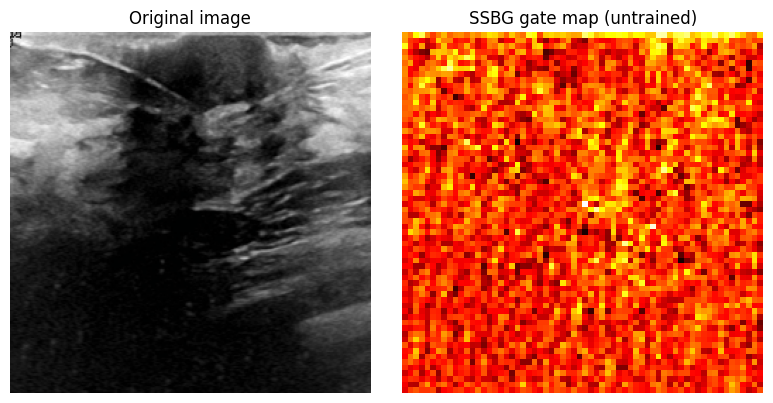

In [ ]:
# CELL 23 - GATE VISUALISATION (UNTRAINED): shows the original image beside the SSBG gate map from cell 22. Illustration only, not a result.
import matplotlib.pyplot as plt
import numpy as np

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img = real_image[0].cpu().permute(1, 2, 0).numpy()
img = (img * std + mean).clip(0, 1)

gate_map = g_real[0, 0].cpu().numpy()  # [64, 64]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img); axes[0].set_title("Original image"); axes[0].axis('off')
axes[1].imshow(gate_map, cmap='hot'); axes[1].set_title("SSBG gate map (untrained)"); axes[1].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 24 - TIER 2 (D-SAS) SECTION: AAS + SFH + FULL MODEL ASSEMBLY
# Purpose: complete the reproduced D-SAS architecture by adding the multi-scale
# semantic branch (AAS) and the fusion head (SFH), then assemble
# backbone + SSBG + AAS + SFH + decoder into one end-to-end model.
# ============================================================

In [ ]:
# CELL 25 - AAS (Adaptive Atrous Selector): semantic branch on the 16x16 high-level features; 4 dilated convs (1,2,4,6) + global pooling, combined with per-pixel softmax weights. Layer names must not change (checkpoints).
import torch.nn.functional as F

class AAS(nn.Module):
    def __init__(self, in_ch=256, out_ch=256, dilations=(1, 2, 4, 6)):
        super().__init__()
        self.branches = nn.ModuleList()
        for d in dilations:
            # d=1 gives a standard 3x3 conv; d>1 gives dilated (atrous) convs
            conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=d, dilation=d)
            self.branches.append(nn.Sequential(conv, nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)))

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.global_conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )

        self.gate = nn.Sequential(
            nn.Conv2d(out_ch * 5, out_ch, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, 5, 1)  # 5 branches -> 5 weight maps
        )
        self.final = nn.Sequential(nn.Conv2d(out_ch, out_ch, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.dropout = nn.Dropout(0.1)

    def forward(self, x):
        H, W = x.shape[2], x.shape[3]
        feats = [branch(x) for branch in self.branches]

        global_feat = self.global_conv(self.global_pool(x))
        global_feat = F.interpolate(global_feat, size=(H, W), mode='bilinear', align_corners=False)
        feats.append(global_feat)  # now 5 feature maps total

        concat = torch.cat(feats, dim=1)          # [B, out_ch*5, H, W]
        weights_raw = self.gate(concat)            # [B, 5, H, W]
        weights = torch.softmax(weights_raw, dim=1) # per-pixel weights across the 5 branches

        stacked = torch.stack(feats, dim=1)         # [B, 5, out_ch, H, W]
        weighted_sum = (stacked * weights.unsqueeze(2)).sum(dim=1)  # [B, out_ch, H, W]

        out = self.dropout(self.final(weighted_sum))
        return out

aas = AAS(in_ch=256, out_ch=256).to(device)
f_aas = aas(f_high_reduced)
print("F_aas:", f_aas.shape)  # expect [2, 256, 16, 16]

F_aas: torch.Size([2, 256, 16, 16])


In [ ]:
# CELL 26 - AAS WEIGHT CHECK: confirms the 5 branch weights per pixel have shape [B,5,16,16] and sum to ~1.0 (softmax). Sanity check only.
with torch.no_grad():
    H, W = f_high_reduced.shape[2], f_high_reduced.shape[3]
    feats_test = [branch(f_high_reduced) for branch in aas.branches]
    global_feat_test = F.interpolate(aas.global_conv(aas.global_pool(f_high_reduced)), size=(H, W), mode='bilinear', align_corners=False)
    feats_test.append(global_feat_test)
    concat_test = torch.cat(feats_test, dim=1)
    weights_test = torch.softmax(aas.gate(concat_test), dim=1)

    print("Weights shape:", weights_test.shape)          # expect [2, 5, 16, 16]
    print("Sum across branches (should be ~1.0):", weights_test.sum(dim=1)[0,0,0].item())

Weights shape: torch.Size([2, 5, 16, 16])
Sum across branches (should be ~1.0): 1.0


In [ ]:
# CELL 27 - AAS ON A REAL IMAGE: runs the real test image from cell 22 through backbone -> high-level channel reduction -> AAS.
reduce_high.eval()
aas.eval()
with torch.no_grad():
    f_low_real, f_high_real = backbone(real_image)
    f_high_real_reduced = reduce_high(f_high_real)
    f_aas_real = aas(f_high_real_reduced)
print("F_aas on real image:", f_aas_real.shape)

F_aas on real image: torch.Size([1, 256, 16, 16])


In [ ]:
# CELL 28 - SFH (Synergistic Fusion Head): upsamples AAS to 64x64, gates both branches, and fuses them by inverse-uncertainty weighting at each pixel. Layer names must not change (checkpoints).
class SFH(nn.Module):
    def __init__(self, ch=256, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.gate_l = nn.Sequential(nn.Conv2d(ch * 2, ch, 1), nn.BatchNorm2d(ch), nn.Sigmoid())
        self.gate_h = nn.Sequential(nn.Conv2d(ch * 2, ch, 1), nn.BatchNorm2d(ch), nn.Sigmoid())
        self.conv_l = nn.Conv2d(ch, 1, 1)
        self.conv_h = nn.Conv2d(ch, 1, 1)
        self.out_proj = nn.Sequential(nn.Conv2d(ch, ch, 1), nn.BatchNorm2d(ch), nn.ReLU(inplace=True))

    def forward(self, f_low, f_high):
        f_high_up = F.interpolate(f_high, size=f_low.shape[2:], mode='bilinear', align_corners=False)

        cat_l = torch.cat([f_low, f_high_up], dim=1)
        cat_h = torch.cat([f_high_up, f_low], dim=1)

        g_l = self.gate_l(cat_l)
        g_h = self.gate_h(cat_h)

        f_l_hat = f_low * g_l
        f_h_hat = f_high_up * g_h

        ul = F.softplus(self.conv_l(f_l_hat)) + self.eps
        uh = F.softplus(self.conv_h(f_h_hat)) + self.eps

        fused = (f_l_hat / ul + f_h_hat / uh) / (1 / ul + 1 / uh)
        return self.out_proj(fused)

sfh = SFH(ch=256).to(device)
f_sfh = sfh(f_ssbg, f_aas)
print("F_sfh:", f_sfh.shape)  # expect [2, 256, 64, 64]

F_sfh: torch.Size([2, 256, 64, 64])


In [ ]:
# CELL 29 - UNCERTAINTY CHECK: prints min/max of SFH's low-level uncertainty on dummy input; must be > 0 so the fusion division is safe. Sanity check only.
with torch.no_grad():
    f_high_up = F.interpolate(f_aas, size=f_ssbg.shape[2:], mode='bilinear', align_corners=False)
    cat_l = torch.cat([f_ssbg, f_high_up], dim=1)
    g_l = sfh.gate_l(cat_l)
    f_l_hat = f_ssbg * g_l
    ul = F.softplus(sfh.conv_l(f_l_hat)) + sfh.eps
    print("ul min/max (should be > 0):", ul.min().item(), ul.max().item())

ul min/max (should be > 0): 0.3532998561859131 0.819847583770752


In [ ]:
# CELL 30 - SFH ON A REAL IMAGE: fuses the real-image SSBG and AAS outputs (from cells 22 and 27) and prints the shape. Check only.
with torch.no_grad():
    f_ssbg_real = ssbg(f_low_real_reduced)
    f_sfh_real = sfh(f_ssbg_real, f_aas_real)
print("F_sfh on real image:", f_sfh_real.shape)

F_sfh on real image: torch.Size([1, 256, 64, 64])


In [ ]:
# CELL 31 - FULL D-SAS MODEL: backbone -> channel reduction -> SSBG (boundary) + AAS (semantic) -> SFH (fusion) -> decoder -> 256x256 mask logits. Attribute names must not change (checkpoints).
class DSASDecoder(nn.Module):
    def __init__(self, ch=256):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch), nn.ReLU(inplace=True))
        self.final = nn.Conv2d(ch, 1, kernel_size=1)

    def forward(self, x, out_size):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.final(x)
        return F.interpolate(x, size=out_size, mode='bilinear', align_corners=False)


class DSAS(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = D_SAS_Backbone()
        self.reduce_low = ChannelReduce(256, 256)
        self.reduce_high = ChannelReduce(2048, 256)
        self.ssbg = SSBG(ch=256)
        self.aas = AAS(in_ch=256, out_ch=256)
        self.sfh = SFH(ch=256)
        self.decoder = DSASDecoder(ch=256)

    def forward(self, x):
        out_size = x.shape[2:]
        f_low, f_high = self.backbone(x)
        f_low_r = self.reduce_low(f_low)
        f_high_r = self.reduce_high(f_high)
        f_ssbg_out = self.ssbg(f_low_r)
        f_aas_out = self.aas(f_high_r)
        f_sfh_out = self.sfh(f_ssbg_out, f_aas_out)
        return self.decoder(f_sfh_out, out_size)

dsas_model = DSAS().to(device)
test_input = torch.randn(2, 3, 256, 256).to(device)
output = dsas_model(test_input)
print("D-SAS output shape:", output.shape)  # expect [2, 1, 256, 256]
print("Total params:", sum(p.numel() for p in dsas_model.parameters()))

D-SAS output shape: torch.Size([2, 1, 256, 256])
Total params: 47500873


In [ ]:
#CELL 33 - TIER 2 (D-SAS) TRAINING (seed 42) - ARCHIVED, DO NOT RUN. Already trained; running it again overwrites dsas_best.pth and changes every result. Kept only as a record of how the model was trained.

# ============================================================
# WEEK 5 — D-SAS Tier 2: Training and Evaluation
# ============================================================
set_seed(42)
dsas_model = DSAS().to(device)
optimizer = torch.optim.Adam(dsas_model.parameters(), lr=1e-4)
loss_fn = DiceBCELoss()

DSAS_PROJECT_DIR = f'{FINAL_DIR}/tier2_dsas'
os.makedirs(f'{DSAS_PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{DSAS_PROJECT_DIR}/logs', exist_ok=True)

NUM_EPOCHS, PATIENCE = 50, 10
best_val_dice, epochs_no_improve = 0.0, 0
checkpoint_path = f'{DSAS_PROJECT_DIR}/checkpoints/dsas_best.pth'
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss = train_one_epoch(dsas_model, train_loader, optimizer, loss_fn, device)
    val_loss, val_metrics = validate(dsas_model, val_loader, loss_fn, device)
    history.append({'epoch': epoch+1, 'train_loss': train_loss, 'val_loss': val_loss, **val_metrics})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | train_loss: {train_loss:.4f} | val_loss: {val_loss:.4f} "
          f"| val_dice: {val_metrics['dice']:.4f} | val_iou: {val_metrics['iou']:.4f} | {time.time()-start:.1f}s")
    if val_metrics['dice'] > best_val_dice:
        best_val_dice, epochs_no_improve = val_metrics['dice'], 0
        torch.save(dsas_model.state_dict(), checkpoint_path)
        print("  -> new best, saved")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

pd.DataFrame(history).to_csv(f'{DSAS_PROJECT_DIR}/logs/training_history.csv', index=False)
print(f"\nD-SAS training complete. Best val Dice: {best_val_dice:.4f}")

In [ ]:
# ============================================================
# CELL 36 - TIER 3 (CA-BSNet, PROPOSED): D-SAS + cross-attention between AAS and SFH.
# Q comes from AAS (semantic, 16x16); K and V come from SSBG (boundary, resized to 16x16).
# This is true cross-attention, not self-attention. Layer names must not change (checkpoints).
# ============================================================

class CrossAttentionBlock(nn.Module):
    """
    Semantic-guided boundary cross-attention.

    Q  = AAS semantic features
    K,V = SSBG boundary features

    AAS:
        [B, 256, 16, 16]

    SSBG:
        [B, 256, 64, 64]

    Output:
        [B, 256, 16, 16]
    """

    def __init__(self, ch=256, num_heads=4, mlp_ratio=2):
        super().__init__()

        self.norm_q = nn.LayerNorm(ch)
        self.norm_kv = nn.LayerNorm(ch)

        self.q_proj = nn.Linear(ch, ch)
        self.k_proj = nn.Linear(ch, ch)
        self.v_proj = nn.Linear(ch, ch)

        self.attn = nn.MultiheadAttention(
            embed_dim=ch,
            num_heads=num_heads,
            batch_first=True
        )

        self.out_proj = nn.Linear(ch, ch)

        self.norm2 = nn.LayerNorm(ch)

        self.mlp = nn.Sequential(
            nn.Linear(ch, ch * mlp_ratio),
            nn.GELU(),
            nn.Linear(ch * mlp_ratio, ch)
        )

    def forward(self, f_aas, f_ssbg):

        # SSBG: [B,256,64,64]
        # Resize to AAS resolution: [B,256,16,16]
        f_ssbg_small = F.interpolate(
            f_ssbg,
            size=f_aas.shape[2:],
            mode='bilinear',
            align_corners=False
        )

        # Convert feature maps to tokens
        q_tokens = f_aas.flatten(2).transpose(1, 2)
        kv_tokens = f_ssbg_small.flatten(2).transpose(1, 2)

        # Q from AAS
        q_norm = self.norm_q(q_tokens)
        q = self.q_proj(q_norm)

        # K,V from SSBG
        kv_norm = self.norm_kv(kv_tokens)
        k = self.k_proj(kv_norm)
        v = self.v_proj(kv_norm)

        # TRUE CROSS-ATTENTION
        attn_out, attn_weights = self.attn(
            query=q,
            key=k,
            value=v,
            need_weights=True
        )

        # Residual
        tokens = q_tokens + self.out_proj(attn_out)

        # Feed-forward
        tokens = tokens + self.mlp(self.norm2(tokens))

        # Back to feature map
        B, N, C = tokens.shape
        H, W = f_aas.shape[2:]

        out = tokens.transpose(1, 2).reshape(B, C, H, W)

        return out, attn_weights


# ============================================================
# CORRECTED CA-BSNet
# ============================================================

class CABSNet(nn.Module):

    def __init__(self):
        super().__init__()

        # D-SAS backbone
        self.backbone = D_SAS_Backbone()

        self.reduce_low = ChannelReduce(256, 256)
        self.reduce_high = ChannelReduce(2048, 256)

        # D-SAS modules
        self.ssbg = SSBG(ch=256)
        self.aas = AAS(in_ch=256, out_ch=256)

        # NEW MODULE
        self.cross_attn = CrossAttentionBlock(
            ch=256,
            num_heads=4,
            mlp_ratio=2
        )

        # D-SAS modules
        self.sfh = SFH(ch=256)
        self.decoder = DSASDecoder(ch=256)

    def forward(self, x):

        out_size = x.shape[2:]

        # Backbone
        f_low, f_high = self.backbone(x)

        # Channel reduction
        f_low_r = self.reduce_low(f_low)
        f_high_r = self.reduce_high(f_high)

        # SSBG
        f_ssbg_out = self.ssbg(f_low_r)

        # AAS
        f_aas_out = self.aas(f_high_r)

        # ====================================================
        # NEW CROSS-ATTENTION
        # Q  = AAS
        # K,V = SSBG
        # ====================================================
        f_ca_out, _ = self.cross_attn(
            f_aas_out,
            f_ssbg_out
        )

        # SFH
        f_sfh_out = self.sfh(
            f_ssbg_out,
            f_ca_out
        )

        # Decoder
        output = self.decoder(
            f_sfh_out,
            out_size
        )

        return output


# ============================================================
# SANITY CHECK
# ============================================================

set_seed(42)

ca_bsnet_model = CABSNet().to(device)
ca_bsnet_model.eval()

test_input = torch.randn(
    2, 3, 256, 256
).to(device)

with torch.no_grad():
    test_output = ca_bsnet_model(test_input)

print("CA-BSNet output shape:", test_output.shape)
print("Expected: [2, 1, 256, 256]")

print(
    "Total parameters:",
    sum(p.numel() for p in ca_bsnet_model.parameters())
)

print(
    "Cross-attention parameters:",
    sum(p.numel() for p in ca_bsnet_model.cross_attn.parameters())
)

CA-BSNet output shape: torch.Size([2, 1, 256, 256])
Expected: [2, 1, 256, 256]
Total parameters: 48291657
Cross-attention parameters: 790784


In [ ]:
# CELL 37 - CROSS-ATTENTION SANITY CHECK: shows Q (AAS) and K/V (SSBG) shapes, attention matrix [B,256,256], and that attention rows sum to 1. Evidence that CA-BSNet is true cross-attention.

ca_bsnet_model.eval()

with torch.no_grad():

    f_low, f_high = ca_bsnet_model.backbone(test_input)

    f_low_r = ca_bsnet_model.reduce_low(f_low)
    f_high_r = ca_bsnet_model.reduce_high(f_high)

    f_ssbg = ca_bsnet_model.ssbg(f_low_r)
    f_aas = ca_bsnet_model.aas(f_high_r)

    f_ca, attn_weights = ca_bsnet_model.cross_attn(
        f_aas,
        f_ssbg
    )

print("SSBG:", f_ssbg.shape)
print("AAS :", f_aas.shape)
print("CA  :", f_ca.shape)
print("Attention:", attn_weights.shape)

print(
    "Attention row-sum:",
    attn_weights.sum(dim=-1).min().item(),
    attn_weights.sum(dim=-1).max().item()
)

SSBG: torch.Size([2, 256, 64, 64])
AAS : torch.Size([2, 256, 16, 16])
CA  : torch.Size([2, 256, 16, 16])
Attention: torch.Size([2, 256, 256])
Attention row-sum: 0.9999998807907104 1.0000001192092896


#CELL 38 - CA-BSNet TRAINING SETUP (seed 42) - ARCHIVED, DO NOT RUN. Together with cell 39 it retrains CA-BSNet and would overwrite cabsnet_best.pth.
set_seed(42)
ca_bsnet_model = CABSNet().to(device)

optimizer = torch.optim.Adam(
    ca_bsnet_model.parameters(),
    lr=1e-4
)

loss_fn = DiceBCELoss()

#CELL 39 - TIER 3 (CA-BSNet) TRAINING (seed 42) - ARCHIVED, DO NOT RUN. Already trained; running it again overwrites cabsnet_best.pth and changes every result. Kept only as a record of how the model was trained.

CA_BSNET_PROJECT_DIR = f'{FINAL_DIR}/tier3_cabsnet'

os.makedirs(f'{CA_BSNET_PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{CA_BSNET_PROJECT_DIR}/logs', exist_ok=True)

NUM_EPOCHS = 50
PATIENCE = 10

best_val_dice = 0.0
epochs_no_improve = 0

checkpoint_path = f'{CA_BSNET_PROJECT_DIR}/checkpoints/cabsnet_best.pth'

history = []

for epoch in range(NUM_EPOCHS):

    start = time.time()

    # -------------------------
    # Training
    # -------------------------
    train_loss = train_one_epoch(
        ca_bsnet_model,
        train_loader,
        optimizer,
        loss_fn,
        device
    )

    # -------------------------
    # Validation
    # -------------------------
    val_loss, val_metrics = validate(
        ca_bsnet_model,
        val_loader,
        loss_fn,
        device
    )

    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        **val_metrics
    })

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"train_loss: {train_loss:.4f} | "
        f"val_loss: {val_loss:.4f} | "
        f"val_dice: {val_metrics['dice']:.4f} | "
        f"val_iou: {val_metrics['iou']:.4f} | "
        f"{time.time()-start:.1f}s"
    )

    # -------------------------
    # Save best checkpoint
    # -------------------------
    if val_metrics['dice'] > best_val_dice:

        best_val_dice = val_metrics['dice']
        epochs_no_improve = 0

        torch.save(
            ca_bsnet_model.state_dict(),
            checkpoint_path
        )

        print("  -> new best, saved")

    else:

        epochs_no_improve += 1

        if epochs_no_improve >= PATIENCE:

            print(
                f"Early stopping at epoch {epoch+1}"
            )

            break


# ============================================================
# Save training history
# ============================================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    f'{CA_BSNET_PROJECT_DIR}/logs/training_history.csv',
    index=False
)

print(
    f"\nCA-BSNet training complete. "
    f"Best val Dice: {best_val_dice:.4f}"
)

print(
    "Checkpoint:",
    checkpoint_path
)

# ============================================================
# 3-SEED ROBUSTNESS EXPERIMENT
# D-SAS vs CORRECTED CA-BSNet
# Seeds 42, 43, 44
# ============================================================
#CELL 48 - OLD 3-SEED TRAINING SCRIPT (D-SAS and CA-BSNet, seeds 43/44) - ARCHIVED, DO NOT RUN. Running it retrains the models and overwrites the saved seed checkpoints. Its hardcoded seed-42 numbers (0.6140 / 0.6276) are from an old run and must not be quoted. Kept only as a record of how the seed runs were produced.
import os
import json
import time
import copy
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

SEEDS = [43, 44]   # Seed 42 already completed
NUM_EPOCHS = 50
PATIENCE = 10
LR = 1e-4

DSAS_DIR = f"{FINAL_DIR}/tier2_dsas"
CABSNET_DIR = f"{FINAL_DIR}/tier3_cabsnet"

os.makedirs(f"{DSAS_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{DSAS_DIR}/logs", exist_ok=True)

os.makedirs(f"{CABSNET_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{CABSNET_DIR}/logs", exist_ok=True)

# ------------------------------------------------------------
# EXISTING SEED-42 RESULTS
# These are the results you already obtained.
# ------------------------------------------------------------

seed42_results = {
    "dsas": {
        "seed": 42,
        "dice": 0.6140,
        "iou": 0.4897,
        "precision": 0.6936,
        "recall": 0.5567,
        "specificity": 0.9693,
        "hd95_mean": 35.2437,
        "hd95_median": 17.0352
    },

    "ca_bsnet": {
        "seed": 42,
        "dice": 0.6276,
        "iou": 0.5018,
        "precision": 0.7011,
        "recall": 0.5729,
        "specificity": 0.9796,
        "hd95_mean": 34.7361,
        "hd95_median": 19.4648
    }
}

# ------------------------------------------------------------
# STORAGE
# ------------------------------------------------------------

multi_seed_results = {
    "dsas": [seed42_results["dsas"]],
    "ca_bsnet": [seed42_results["ca_bsnet"]]
}

# ------------------------------------------------------------
# TRAINING FUNCTION
# ------------------------------------------------------------

def train_model_for_seed(
    model_name,
    model_class,
    seed,
    checkpoint_path
):

    print("\n" + "=" * 80)
    print(f"SEED {seed} — {model_name}")
    print("=" * 80)

    # --------------------------------------------------------
    # Set seed BEFORE model creation
    # --------------------------------------------------------
    set_seed(seed)

    # --------------------------------------------------------
    # Create fresh model
    # --------------------------------------------------------
    model = model_class().to(device)

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------
    loss_fn = DiceBCELoss()

    best_val_dice = -1.0
    best_epoch = 0
    epochs_no_improve = 0

    training_history = []

    start_total = time.time()

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------
    for epoch in range(NUM_EPOCHS):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            loss_fn,
            device
        )

        val_loss, val_metrics = validate(
            model,
            val_loader,
            loss_fn,
            device
        )

        epoch_time = time.time() - epoch_start

        current_val_dice = val_metrics["dice"]

        training_history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            **val_metrics
        })

        print(
            f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Dice: {current_val_dice:.4f} | "
            f"Time: {epoch_time:.1f}s"
        )

        # ----------------------------------------------------
        # Save best model according to validation Dice
        # ----------------------------------------------------
        if current_val_dice > best_val_dice:

            best_val_dice = current_val_dice
            best_epoch = epoch + 1
            epochs_no_improve = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print(
                f"  -> New best model saved "
                f"(Val Dice: {best_val_dice:.4f})"
            )

        else:

            epochs_no_improve += 1

            if epochs_no_improve >= PATIENCE:

                print(
                    f"  -> Early stopping at epoch "
                    f"{epoch + 1}"
                )

                break

    total_time = time.time() - start_total

    # --------------------------------------------------------
    # Save training history
    # --------------------------------------------------------

    history_df = pd.DataFrame(training_history)

    model_key = (
        "dsas"
        if model_name == "D-SAS"
        else "ca_bsnet"
    )

    history_path = os.path.join(
        os.path.dirname(os.path.dirname(checkpoint_path)),
        "logs",
        f"training_history_seed{seed}.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print("\nTraining complete.")
    print(f"Best epoch      : {best_epoch}")
    print(f"Best Val Dice   : {best_val_dice:.4f}")
    print(f"Total time      : {total_time / 60:.2f} minutes")

    # --------------------------------------------------------
    # Load BEST checkpoint
    # --------------------------------------------------------

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    # --------------------------------------------------------
    # Test evaluation
    # --------------------------------------------------------

    print("\nEvaluating best checkpoint on TEST set...")

    test_loss, test_metrics = validate(
        model,
        test_loader,
        loss_fn,
        device
    )

    result = {
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_dice": float(best_val_dice),
        "test_loss": float(test_loss),

        "dice": float(test_metrics["dice"]),
        "iou": float(test_metrics["iou"]),
        "precision": float(test_metrics["precision"]),
        "recall": float(test_metrics["recall"]),
        "specificity": float(test_metrics["specificity"]),
        "hd95_mean": float(test_metrics["hd95_mean"]),
        "hd95_median": float(test_metrics["hd95_median"])
    }

    print("\nTEST RESULTS")
    print("-" * 50)

    for key, value in result.items():

        if isinstance(value, float):
            print(f"{key:20s}: {value:.4f}")
        else:
            print(f"{key:20s}: {value}")

    # --------------------------------------------------------
    # Save individual seed result
    # --------------------------------------------------------

    result_path = os.path.join(
        os.path.dirname(os.path.dirname(checkpoint_path)),
        "logs",
        f"test_results_seed{seed}.json"
    )

    with open(result_path, "w") as f:
        json.dump(
            result,
            f,
            indent=2
        )

    print(f"\nSaved result: {result_path}")

    # --------------------------------------------------------
    # Free GPU memory
    # --------------------------------------------------------

    del model
    del optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# RUN SEEDS 43 AND 44
# ============================================================

for seed in SEEDS:

    # ========================================================
    # D-SAS
    # ========================================================

    dsas_checkpoint = (
        f"{DSAS_DIR}/checkpoints/"
        f"dsas_seed{seed}.pth"
    )

    dsas_result = train_model_for_seed(
        model_name="D-SAS",
        model_class=DSAS,
        seed=seed,
        checkpoint_path=dsas_checkpoint
    )

    multi_seed_results["dsas"].append(
        dsas_result
    )

    # ========================================================
    # CORRECTED CA-BSNet
    # ========================================================

    ca_checkpoint = (
        f"{CABSNET_DIR}/checkpoints/"
        f"cabsnet_seed{seed}.pth"
    )

    ca_result = train_model_for_seed(
        model_name="CA-BSNet (Corrected)",
        model_class=CABSNet,
        seed=seed,
        checkpoint_path=ca_checkpoint
    )

    multi_seed_results["ca_bsnet"].append(
        ca_result
    )


# ============================================================
# SAVE COMPLETE RAW RESULTS
# ============================================================

raw_results_path = (
    f"{FINAL_DIR}/multi_seed_results_42_43_44.json"
)

with open(raw_results_path, "w") as f:

    json.dump(
        multi_seed_results,
        f,
        indent=2
    )

print("\n" + "=" * 80)
print("RAW MULTI-SEED RESULTS SAVED")
print("=" * 80)
print(raw_results_path)


# ============================================================
# CALCULATE MEAN ± STD
# ============================================================

METRICS = [
    "dice",
    "iou",
    "precision",
    "recall",
    "specificity",
    "hd95_mean",
    "hd95_median"
]

metric_names = {
    "dice": "Dice",
    "iou": "IoU",
    "precision": "Precision",
    "recall": "Recall",
    "specificity": "Specificity",
    "hd95_mean": "HD95 Mean",
    "hd95_median": "HD95 Median"
}

summary_rows = []

for model_key, model_results in multi_seed_results.items():

    row = {
        "Model": (
            "D-SAS"
            if model_key == "dsas"
            else "CA-BSNet (Corrected)"
        )
    }

    for metric in METRICS:

        values = [
            float(result[metric])
            for result in model_results
        ]

        mean_value = np.mean(values)

        # Sample standard deviation
        std_value = np.std(
            values,
            ddof=1
        )

        row[metric_names[metric]] = (
            f"{mean_value:.4f} ± {std_value:.4f}"
        )

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# PRINT FINAL TABLE
# ============================================================

print("\n")
print("=" * 110)
print("FINAL 3-SEED COMPARISON")
print("Seeds: 42, 43, 44")
print("=" * 110)

print(
    summary_df.to_string(
        index=False
    )
)


# ============================================================
# NUMERICAL MEANS FOR DIRECT COMPARISON
# ============================================================

print("\n")
print("=" * 80)
print("NUMERICAL MEANS")
print("=" * 80)

for model_key, model_results in multi_seed_results.items():

    model_name = (
        "D-SAS"
        if model_key == "dsas"
        else "CA-BSNet (Corrected)"
    )

    print(f"\n{model_name}")

    for metric in METRICS:

        values = [
            float(result[metric])
            for result in model_results
        ]

        mean_value = np.mean(values)
        std_value = np.std(
            values,
            ddof=1
        )

        print(
            f"{metric_names[metric]:15s}: "
            f"{mean_value:.4f} ± {std_value:.4f}"
        )


# ============================================================
# CA-BSNet IMPROVEMENT OVER D-SAS
# ============================================================

print("\n")
print("=" * 80)
print("CA-BSNet vs D-SAS — MEAN DIFFERENCE")
print("=" * 80)

dsas_data = multi_seed_results["dsas"]
ca_data = multi_seed_results["ca_bsnet"]

for metric in METRICS:

    dsas_values = np.array([
        float(r[metric])
        for r in dsas_data
    ])

    ca_values = np.array([
        float(r[metric])
        for r in ca_data
    ])

    dsas_mean = np.mean(dsas_values)
    ca_mean = np.mean(ca_values)

    difference = ca_mean - dsas_mean

    # For HD95, lower is better
    direction = "better" if (
        difference > 0
        if metric not in ["hd95_mean", "hd95_median"]
        else difference < 0
    ) else "worse"

    print(
        f"{metric_names[metric]:15s}: "
        f"{difference:+.4f} ({direction})"
    )


# ============================================================
# SAVE SUMMARY CSV
# ============================================================

summary_csv_path = (
    f"{FINAL_DIR}/multi_seed_summary_42_43_44.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False
)

print("\n")
print("=" * 80)
print("SUMMARY SAVED")
print("=" * 80)
print(summary_csv_path)


# ============================================================
# SAVE DETAILED NUMERICAL SUMMARY JSON
# ============================================================

numerical_summary = {}

for model_key, model_results in multi_seed_results.items():

    model_name = (
        "D-SAS"
        if model_key == "dsas"
        else "CA-BSNet (Corrected)"
    )

    numerical_summary[model_name] = {}

    for metric in METRICS:

        values = [
            float(r[metric])
            for r in model_results
        ]

        numerical_summary[model_name][metric] = {
            "values": values,
            "mean": float(np.mean(values)),
            "std": float(np.std(values, ddof=1))
        }


numerical_json_path = (
    f"{FINAL_DIR}/multi_seed_numerical_summary.json"
)

with open(numerical_json_path, "w") as f:

    json.dump(
        numerical_summary,
        f,
        indent=2
    )

print(numerical_json_path)

print("\n")
print("=" * 80)
print("3-SEED EXPERIMENT COMPLETE")
print("=" * 80)

#CELL 96 - TIER 1 TRAINING FOR SEEDS 43 AND 44 - ARCHIVED, DO NOT RUN. Running it retrains Attention U-Net and overwrites attention_unet_seed43.pth and attention_unet_seed44.pth, which the final evaluation reads. Kept only as a record of how those checkpoints were produced.
for seed in [43, 44]:
    set_seed(seed)
    model = AttentionUNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = DiceBCELoss()

    NUM_EPOCHS, PATIENCE = 50, 10
    best_val_dice, epochs_no_improve = 0.0, 0
    checkpoint_path = f'{PROJECT_DIR}/checkpoints/attention_unet_seed{seed}.pth'
    history = []

    for epoch in range(NUM_EPOCHS):
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
        val_loss, val_metrics = validate(model, val_loader, loss_fn, device)
        history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss, **val_metrics})
        if val_metrics['dice'] > best_val_dice:
            best_val_dice, epochs_no_improve = val_metrics['dice'], 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Seed {seed} early stopping at epoch {epoch+1}")
            break

    pd.DataFrame(history).to_csv(f'{PROJECT_DIR}/logs/training_history_seed{seed}.csv', index=False)

    model.load_state_dict(torch.load(checkpoint_path))
    model.eval()
    test_loss, test_metrics = validate(model, test_loader, loss_fn, device)
    results_summary = {'model': f'Attention U-Net (Tier 1, seed {seed})',
                        'dataset': f'BUSI ({len(kept_records)} images, deduplicated, 70/15/15 split)',
                        **test_metrics}
    with open(f'{PROJECT_DIR}/logs/test_results_seed{seed}.json', 'w') as f:
        json.dump(results_summary, f, indent=2)

    print(f"Seed {seed} done. Best val Dice: {best_val_dice:.4f}, Test Dice: {test_metrics['dice']:.4f}")

In [ ]:
# CELL 124 - FINAL EVALUATION HELPERS: per-image metrics (collect_per_image_metrics), per-model summary (summarize), paired bootstrap CI (bootstrap_ci). The only copy of these functions.
def collect_per_image_metrics(model, loader, device):
    model.eval(); records = []
    with torch.no_grad():
        for batch in loader:
            images, masks = batch["image"].to(device), batch["mask"].to(device)
            preds = model(images)
            for i in range(images.shape[0]):
                m = compute_metrics(preds[i:i+1], masks[i:i+1])
                pred_bin = (torch.sigmoid(preds[i:i+1]) > 0.5).cpu().numpy().astype(bool)[0, 0]
                gt_bin = masks[i:i+1].cpu().numpy().astype(bool)[0, 0]
                m['hd95'] = compute_hd95_single(pred_bin, gt_bin)
                records.append(m)
    return records

def summarize(per_image_records, model_name):
    hd95_vals = [r['hd95'] for r in per_image_records if r['hd95'] is not None]
    return {
        'model': model_name,
        'dice': float(np.mean([r['dice'] for r in per_image_records])),
        'iou': float(np.mean([r['iou'] for r in per_image_records])),
        'precision': float(np.mean([r['precision'] for r in per_image_records])),
        'recall': float(np.mean([r['recall'] for r in per_image_records])),
        'specificity': float(np.mean([r['specificity'] for r in per_image_records])),
        'accuracy': float(np.mean([r['accuracy'] for r in per_image_records])),
        'hd95_mean': float(np.mean(hd95_vals)) if hd95_vals else float('nan'),
        'hd95_median': float(np.median(hd95_vals)) if hd95_vals else float('nan'),
        'hd95_valid_count': len(hd95_vals),
        'n_images': len(per_image_records),
    }

def bootstrap_ci(values_a, values_b, n_iterations=1000, seed=42):
    rng = np.random.RandomState(seed); n = len(values_a); diffs = []
    for _ in range(n_iterations):
        idx = rng.randint(0, n, size=n)
        diffs.append(np.mean([values_b[i] for i in idx]) - np.mean([values_a[i] for i in idx]))
    diffs = np.array(diffs)
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

print("collect_per_image_metrics, summarize, bootstrap_ci ready")

collect_per_image_metrics, summarize, bootstrap_ci ready


In [ ]:
# CELL 125 - READINESS CHECK: confirms the three model classes, compute_metrics, compute_hd95_single and test_loader exist before the final evaluation. All six must print True.
print('AttentionUNet' in dir(), 'DSAS' in dir(), 'CABSNet' in dir(), 'compute_metrics' in dir(),
      'compute_hd95_single' in dir(), 'test_loader' in dir())


True True True True True True


In [ ]:
# NEW CELL - ONE-TIME RETRAIN of seeds 43/44 for all 3 models on the FROZEN split (old seed43/44 were trained on an earlier split).
# Safe to re-run: finished runs are skipped; checkpoints are written as .inprogress and renamed only when the run completes.
import shutil, json, hashlib

def file_md5(p): return hashlib.md5(open(p, 'rb').read()).hexdigest()
SPLIT_FP = {k: file_md5(f'{FINAL_DIR}/{k}.csv') for k in ['train', 'val', 'test']}

TRAIN_SPECS = {'attention_unet': ('tier1_attention_unet', AttentionUNet),
               'dsas':           ('tier2_dsas', DSAS),
               'cabsnet':        ('tier3_cabsnet', CABSNet)}
ARCHIVE = f'{FINAL_DIR}/old_split_checkpoints_seed43_44'
BACKUP_NEW = '/content/drive/MyDrive/BUSI_FROZEN_BACKUP/retrained_seed43_44'
os.makedirs(ARCHIVE, exist_ok=True); os.makedirs(BACKUP_NEW, exist_ok=True)

# 1) Archive old seed43/44 checkpoints (no .json fingerprint = trained on the old split)
for name, (tier_dir, _) in TRAIN_SPECS.items():
    for seed in (43, 44):
        final = f'{FINAL_DIR}/{tier_dir}/checkpoints/{name}_seed{seed}.pth'
        if os.path.exists(final) and not os.path.exists(final + '.json'):
            shutil.move(final, f'{ARCHIVE}/{name}_seed{seed}.pth')
            print(f"Archived old {name} seed{seed} -> {ARCHIVE}")

# 2) Train one (model, seed) run
def train_run(name, seed, num_epochs=50, patience=10, lr=1e-4):
    tier_dir, cls = TRAIN_SPECS[name]
    ck_dir = f'{FINAL_DIR}/{tier_dir}/checkpoints'; log_dir = f'{FINAL_DIR}/{tier_dir}/logs'
    os.makedirs(ck_dir, exist_ok=True); os.makedirs(log_dir, exist_ok=True)
    final = f'{ck_dir}/{name}_seed{seed}.pth'; tmp = final + '.inprogress'
    if os.path.exists(final) and os.path.exists(final + '.json'):
        meta = json.load(open(final + '.json'))
        assert meta['split_md5'] == SPLIT_FP, f"{final} was trained on a different split!"
        print(f"SKIP {name} seed{seed} (already trained on this split)"); return
    print("\n" + "=" * 70 + f"\nTRAINING {name} seed{seed}\n" + "=" * 70)
    set_seed(seed)
    model = cls().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = DiceBCELoss()
    best_val, best_epoch, no_improve, history = -1.0, 0, 0, []
    t0 = time.time()
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
        val_loss, vm = validate(model, val_loader, loss_fn, device)
        history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss, **vm})
        print(f"Epoch {epoch+1:02d}/{num_epochs} | train {train_loss:.4f} | val {val_loss:.4f} | val_dice {vm['dice']:.4f}")
        if vm['dice'] > best_val:
            best_val, best_epoch, no_improve = vm['dice'], epoch + 1, 0
            torch.save(model.state_dict(), tmp)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping at epoch {epoch+1}"); break
    os.replace(tmp, final)
    pd.DataFrame(history).to_csv(f'{log_dir}/training_history_seed{seed}.csv', index=False)
    json.dump({'split_md5': SPLIT_FP, 'seed': seed, 'best_val_dice': float(best_val), 'best_epoch': best_epoch,
               'epochs_run': len(history), 'minutes': round((time.time() - t0) / 60, 2)}, open(final + '.json', 'w'), indent=2)
    shutil.copy2(final, f'{BACKUP_NEW}/{name}_seed{seed}.pth'); shutil.copy2(final + '.json', f'{BACKUP_NEW}/{name}_seed{seed}.pth.json')
    print(f"DONE {name} seed{seed}: best val Dice {best_val:.4f} at epoch {best_epoch} ({(time.time()-t0)/60:.1f} min)")
    del model, optimizer; torch.cuda.empty_cache()

for seed in (43, 44):
    for name in ('attention_unet', 'dsas', 'cabsnet'):
        train_run(name, seed)
print("\nAll retraining finished.")

SKIP attention_unet seed43 (already trained on this split)
SKIP dsas seed43 (already trained on this split)
SKIP cabsnet seed43 (already trained on this split)
SKIP attention_unet seed44 (already trained on this split)

TRAINING dsas seed44
Epoch 01/50 | train 1.4136 | val 1.3280 | val_dice 0.3118
Epoch 02/50 | train 0.9836 | val 0.9731 | val_dice 0.6026
Epoch 03/50 | train 0.8119 | val 0.7811 | val_dice 0.6859
Epoch 04/50 | train 0.6997 | val 0.7099 | val_dice 0.7090
Epoch 05/50 | train 0.6318 | val 0.6696 | val_dice 0.7225
Epoch 06/50 | train 0.5839 | val 0.6503 | val_dice 0.7383
Epoch 07/50 | train 0.5391 | val 0.5820 | val_dice 0.7637
Epoch 08/50 | train 0.5053 | val 0.5714 | val_dice 0.7454
Epoch 09/50 | train 0.4623 | val 0.5788 | val_dice 0.7514
Epoch 10/50 | train 0.4315 | val 0.5333 | val_dice 0.7471
Epoch 11/50 | train 0.3931 | val 0.5181 | val_dice 0.7537
Epoch 12/50 | train 0.3797 | val 0.5005 | val_dice 0.7653
Epoch 13/50 | train 0.3461 | val 0.4888 | val_dice 0.7675
Epoch

In [ ]:
import json, hashlib
cur = {k: hashlib.md5(open(f'{FINAL_DIR}/{k}.csv', 'rb').read()).hexdigest() for k in ['train', 'val', 'test']}
csv_time = max(os.path.getmtime(f'{FINAL_DIR}/{k}.csv') for k in ['train', 'val', 'test'])
all_ok = True
for tier, name in [('tier1_attention_unet', 'attention_unet'), ('tier2_dsas', 'dsas'), ('tier3_cabsnet', 'cabsnet')]:
    for suf in ['best', 'seed43', 'seed44']:
        p = f'{FINAL_DIR}/{tier}/checkpoints/{name}_{suf}.pth'
        if suf == 'best':   # seed 42: no fingerprint file, so check it was saved after the CSVs were written
            ok = os.path.getmtime(p) > csv_time; how = "saved after CSVs"
        else:               # seeds 43/44: fingerprint stored at training time
            ok = os.path.exists(p + '.json') and json.load(open(p + '.json'))['split_md5'] == cur; how = "split fingerprint"
        all_ok &= ok
        print(f"{'PASS' if ok else 'FAIL'}  {name:<15} {suf:<7} ({how})")
print("\nALL 9 CHECKPOINTS MATCH THE CURRENT SPLIT" if all_ok else "\nMISMATCH - do not evaluate yet")

PASS  attention_unet  best    (saved after CSVs)
PASS  attention_unet  seed43  (split fingerprint)
PASS  attention_unet  seed44  (split fingerprint)
PASS  dsas            best    (saved after CSVs)
PASS  dsas            seed43  (split fingerprint)
PASS  dsas            seed44  (split fingerprint)
PASS  cabsnet         best    (saved after CSVs)
PASS  cabsnet         seed43  (split fingerprint)
PASS  cabsnet         seed44  (split fingerprint)

ALL 9 CHECKPOINTS MATCH THE CURRENT SPLIT


In [ ]:
# CELL 126 - FINAL PER-IMAGE EVALUATION (source of every reported number)
# For each seed (42/43/44) it loads the 3 saved checkpoints from Drive by exact file name, computes per-image metrics,
# averages per seed, then reports mean +/- SD (ddof=1) across seeds for Attention U-Net, D-SAS, CA-BSNet and the 50/50 Ensemble.
# Per-image records of D-SAS and CA-BSNet are kept per seed for the bootstrap in cell 127.
# Output: final_per_image_thesis_table.json on Drive.

def load_ckpt_compat(model, path, device):
    """Load a checkpoint. Seed-42 files were saved with an earlier bias-free ChannelReduce
    (keys 'reduce_*.reduce.*', no conv bias). A conv followed by BatchNorm is equivalent with zero bias,
    so we rename those keys and fill the two biases with zeros. Loading stays strict."""
    sd = torch.load(path, map_location=device)
    fixed = {k.replace('reduce_low.reduce.', 'reduce_low.block.').replace('reduce_high.reduce.', 'reduce_high.block.'): v
             for k, v in sd.items()}
    ref = model.state_dict()
    for k in ('reduce_low.block.0.bias', 'reduce_high.block.0.bias'):
        if k in ref and k not in fixed:
            fixed[k] = torch.zeros_like(ref[k])
    model.load_state_dict(fixed)   # strict: any other mismatch still raises an error
    return model

def collect_per_image_metrics_ensemble(model_a, model_b, loader, device, threshold=0.5):
    model_a.eval(); model_b.eval()
    records = []
    with torch.no_grad():
        for batch in loader:
            images, masks = batch["image"].to(device), batch["mask"].to(device)
            prob = (torch.sigmoid(model_a(images)) + torch.sigmoid(model_b(images))) / 2
            logits_equiv = torch.logit(prob.clamp(1e-6, 1 - 1e-6))  # compute_metrics expects logits
            for i in range(images.shape[0]):
                m = compute_metrics(logits_equiv[i:i+1], masks[i:i+1], threshold=threshold)
                pred_bin = (prob[i:i+1] > threshold).cpu().numpy().astype(bool)[0, 0]
                gt_bin = masks[i:i+1].cpu().numpy().astype(bool)[0, 0]
                m['hd95'] = compute_hd95_single(pred_bin, gt_bin)
                records.append(m)
    return records

seed_ckpt_suffix = {42: 'best', 43: 'seed43', 44: 'seed44'}
per_seed_summaries = {'Attention U-Net': [], 'D-SAS': [], 'CA-BSNet': [], 'Ensemble': []}
dsas_pi_by_seed, cabsnet_pi_by_seed = {}, {}

for seed in [42, 43, 44]:
    suffix = seed_ckpt_suffix[seed]
    au_path = f'{FINAL_DIR}/tier1_attention_unet/checkpoints/attention_unet_{suffix}.pth'
    d_path  = f'{FINAL_DIR}/tier2_dsas/checkpoints/dsas_{suffix}.pth'
    c_path  = f'{FINAL_DIR}/tier3_cabsnet/checkpoints/cabsnet_{suffix}.pth'
    for p in (au_path, d_path, c_path):
        assert os.path.exists(p), f"Missing checkpoint: {p}"

    au = load_ckpt_compat(AttentionUNet().to(device), au_path, device)
    au.eval()
    au_pi = collect_per_image_metrics(au, test_loader, device)
    per_seed_summaries['Attention U-Net'].append(summarize(au_pi, f'Attention U-Net seed{seed}'))

    d = load_ckpt_compat(DSAS().to(device), d_path, device)
    d.eval()
    dsas_pi = collect_per_image_metrics(d, test_loader, device)
    per_seed_summaries['D-SAS'].append(summarize(dsas_pi, f'D-SAS seed{seed}'))

    c = load_ckpt_compat(CABSNet().to(device), c_path, device)
    c.eval()
    cabsnet_pi = collect_per_image_metrics(c, test_loader, device)
    per_seed_summaries['CA-BSNet'].append(summarize(cabsnet_pi, f'CA-BSNet seed{seed}'))

    ens_pi = collect_per_image_metrics_ensemble(d, c, test_loader, device)
    per_seed_summaries['Ensemble'].append(summarize(ens_pi, f'Ensemble seed{seed}'))

    dsas_pi_by_seed[seed] = dsas_pi          # kept for the per-seed bootstrap (cell 127)
    cabsnet_pi_by_seed[seed] = cabsnet_pi

    print(f"Seed {seed} done - AU={per_seed_summaries['Attention U-Net'][-1]['dice']:.4f}, "
          f"D-SAS={per_seed_summaries['D-SAS'][-1]['dice']:.4f}, "
          f"CA-BSNet={per_seed_summaries['CA-BSNet'][-1]['dice']:.4f}, "
          f"Ensemble={per_seed_summaries['Ensemble'][-1]['dice']:.4f}")

    del au, d, c
    torch.cuda.empty_cache()

# ---------- Final table: per-image averaged per seed, then mean +/- SD (ddof=1) across seeds ----------
metrics = ['dice', 'iou', 'precision', 'recall', 'specificity', 'accuracy', 'hd95_mean', 'hd95_median']
final_per_image_table = {}
print(f"\n{'Model':<20}" + "".join(f"{m:>14}" for m in metrics))
for model_name, seed_summaries in per_seed_summaries.items():
    row = {}
    line = f"{model_name:<20}"
    for m in metrics:
        vals = [s[m] for s in seed_summaries]
        mean, std = np.mean(vals), np.std(vals, ddof=1)
        row[m] = {'mean': float(mean), 'std': float(std)}
        line += f"{mean:>9.4f}±{std:.3f}" if m in ('dice','iou','precision','recall','specificity','accuracy') else f"{mean:>10.2f}±{std:.2f}"
    final_per_image_table[model_name] = row
    print(line)

with open(f'{FINAL_DIR}/final_per_image_thesis_table.json', 'w') as f:
    json.dump(final_per_image_table, f, indent=2)
print("\nSaved final_per_image_thesis_table.json")

Seed 42 done - AU=0.6374, D-SAS=0.7526, CA-BSNet=0.7151, Ensemble=0.7455
Seed 43 done - AU=0.6583, D-SAS=0.7398, CA-BSNet=0.7328, Ensemble=0.7414
Seed 44 done - AU=0.6079, D-SAS=0.7137, CA-BSNet=0.7152, Ensemble=0.7289

Model                         dice           iou     precision        recall   specificity      accuracy     hd95_mean   hd95_median
Attention U-Net        0.6345±0.025   0.5226±0.024   0.6552±0.019   0.7617±0.009   0.9633±0.005   0.9411±0.004     59.07±2.56     47.90±5.73
D-SAS                  0.7354±0.020   0.6386±0.023   0.7784±0.039   0.7777±0.022   0.9762±0.004   0.9554±0.005     33.85±2.89     16.09±2.68
CA-BSNet               0.7210±0.010   0.6200±0.011   0.7710±0.025   0.7637±0.027   0.9746±0.002   0.9532±0.001     35.48±3.26     17.85±0.81
Ensemble               0.7386±0.009   0.6432±0.010   0.8000±0.022   0.7740±0.018   0.9784±0.003   0.9573±0.003     32.67±2.21     15.89±3.08

Saved final_per_image_thesis_table.json


In [ ]:
# CELL 127 - PAIRED BOOTSTRAP, CA-BSNet minus D-SAS, run SEPARATELY FOR EACH SEED (1000 resamples of the 81 test images).
# A CI that excludes 0 means a reliable difference for that seed. Uses per-image records kept by cell 126.
# Output: final_bootstrap_cabsnet_vs_dsas.json on Drive.
metrics_bs = ['dice', 'iou', 'precision', 'recall', 'specificity', 'accuracy']
bootstrap_final = {}
for seed in [42, 43, 44]:
    print(f"\n=== Seed {seed} ===")
    print(f"{'Metric':<12} {'D-SAS':>8} {'CA-BSNet':>10} {'Diff':>9} {'95% CI':>22} {'Sig?':>6}")
    bootstrap_final[f'seed{seed}'] = {}
    for metric in metrics_bs:
        a_vals = [m[metric] for m in dsas_pi_by_seed[seed]]
        b_vals = [m[metric] for m in cabsnet_pi_by_seed[seed]]
        mean_diff, ci_low, ci_high = bootstrap_ci(a_vals, b_vals, n_iterations=1000)
        significant = bool(not (ci_low <= 0 <= ci_high))
        bootstrap_final[f'seed{seed}'][metric] = {'dsas': float(np.mean(a_vals)), 'cabsnet': float(np.mean(b_vals)),
            'diff': float(mean_diff), 'ci_low': float(ci_low), 'ci_high': float(ci_high), 'significant': significant}
        print(f"{metric:<12} {np.mean(a_vals):>8.4f} {np.mean(b_vals):>10.4f} {mean_diff:>+9.4f} "
              f"[{ci_low:+.4f}, {ci_high:+.4f}] {'YES' if significant else 'no':>6}")

dice_diffs = [bootstrap_final[f'seed{s}']['dice']['diff'] for s in [42, 43, 44]]
dice_sig = [bootstrap_final[f'seed{s}']['dice']['significant'] for s in [42, 43, 44]]
print(f"\nDice difference (CA-BSNet - D-SAS) per seed: {[round(d, 4) for d in dice_diffs]} | significant in {sum(dice_sig)} of 3 seeds")

with open(f'{FINAL_DIR}/final_bootstrap_cabsnet_vs_dsas.json', 'w') as f:
    json.dump(bootstrap_final, f, indent=2)
print("Saved final_bootstrap_cabsnet_vs_dsas.json")


=== Seed 42 ===
Metric          D-SAS   CA-BSNet      Diff                 95% CI   Sig?
dice           0.7526     0.7151   -0.0371 [-0.0736, -0.0039]    YES
iou            0.6611     0.6132   -0.0476 [-0.0865, -0.0079]    YES
precision      0.8214     0.7993   -0.0207 [-0.0769, +0.0352]     no
recall         0.7737     0.7372   -0.0366 [-0.0667, -0.0087]    YES
specificity    0.9803     0.9763   -0.0039 [-0.0140, +0.0050]     no
accuracy       0.9596     0.9536   -0.0060 [-0.0143, +0.0020]     no

=== Seed 43 ===
Metric          D-SAS   CA-BSNet      Diff                 95% CI   Sig?
dice           0.7398     0.7328   -0.0067 [-0.0375, +0.0200]     no
iou            0.6401     0.6331   -0.0067 [-0.0346, +0.0166]     no
precision      0.7677     0.7520   -0.0157 [-0.0524, +0.0159]     no
recall         0.8013     0.7916   -0.0090 [-0.0404, +0.0184]     no
specificity    0.9764     0.9735   -0.0029 [-0.0076, +0.0012]     no
accuracy       0.9562     0.9535   -0.0026 [-0.0071, +0.0015]

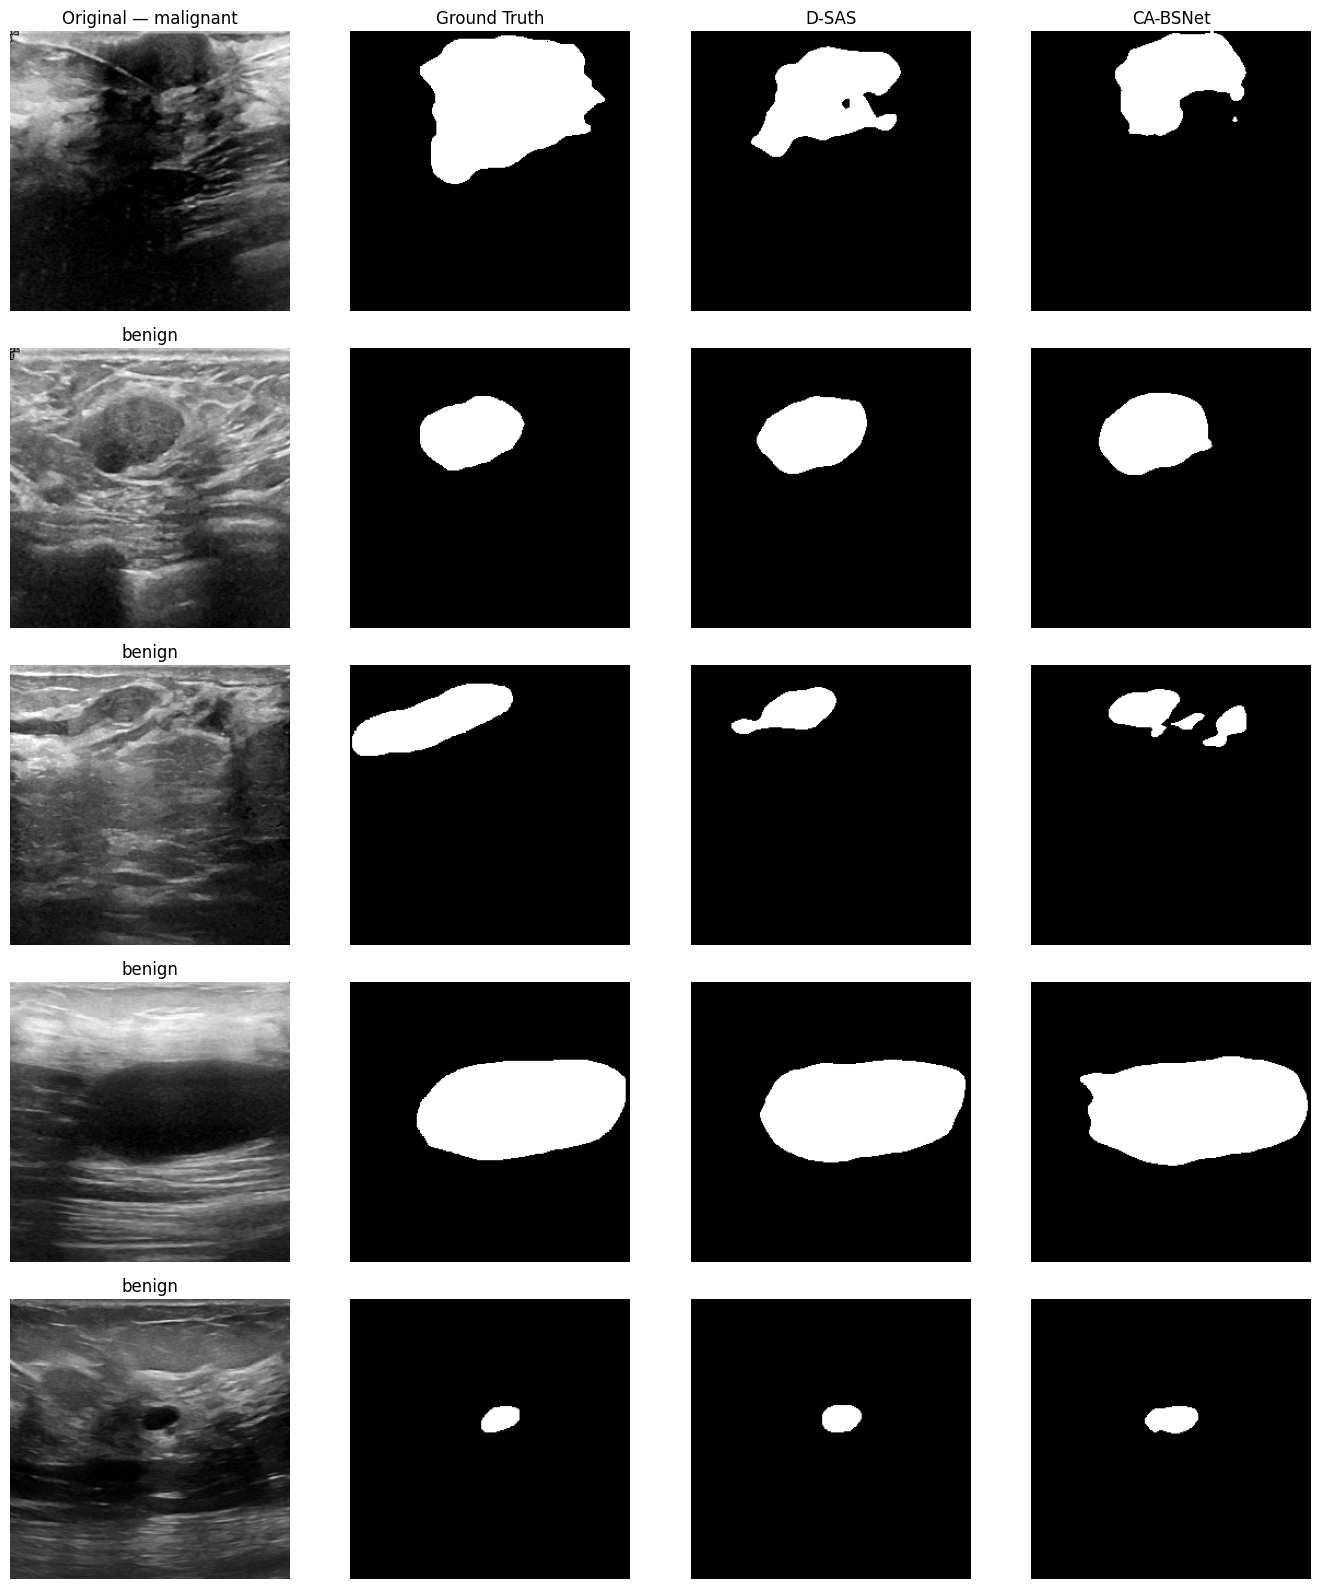

In [ ]:
# CELL 92 - QUALITATIVE COMPARISON FIGURE: loads the saved D-SAS and CA-BSNet checkpoints for one seed and shows
# 5 test images with ground truth and both predictions. Illustration only; state the seed in the report.
# Saves final_comparison_predictions.png for the report/slides. Needs cell 126 to have run (for load_ckpt_compat).
SEED = 42
suffix = {42: 'best', 43: 'seed43', 44: 'seed44'}[SEED]

fig_dsas = load_ckpt_compat(DSAS().to(device), f'{FINAL_DIR}/tier2_dsas/checkpoints/dsas_{suffix}.pth', device); fig_dsas.eval()
fig_cabsnet = load_ckpt_compat(CABSNet().to(device), f'{FINAL_DIR}/tier3_cabsnet/checkpoints/cabsnet_{suffix}.pth', device); fig_cabsnet.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

batch = next(iter(test_loader))
images, masks = batch["image"].to(device), batch["mask"].to(device)

with torch.no_grad():
    dsas_preds = torch.sigmoid(fig_dsas(images)) > 0.5
    cabsnet_preds = torch.sigmoid(fig_cabsnet(images)) > 0.5

n_show = 5
fig, axes = plt.subplots(n_show, 4, figsize=(14, 3.2 * n_show))
for i in range(n_show):
    img = images[i].cpu().permute(1, 2, 0).numpy()
    img = (img * std + mean).clip(0, 1)
    gt = masks[i, 0].cpu().numpy()
    axes[i, 0].imshow(img); axes[i, 0].set_title(f"Original — {batch['class'][i]}" if i == 0 else batch['class'][i]); axes[i, 0].axis('off')
    axes[i, 1].imshow(gt, cmap='gray'); axes[i, 1].set_title("Ground Truth" if i == 0 else ""); axes[i, 1].axis('off')
    axes[i, 2].imshow(dsas_preds[i, 0].cpu().numpy(), cmap='gray'); axes[i, 2].set_title("D-SAS" if i == 0 else ""); axes[i, 2].axis('off')
    axes[i, 3].imshow(cabsnet_preds[i, 0].cpu().numpy(), cmap='gray'); axes[i, 3].set_title("CA-BSNet" if i == 0 else ""); axes[i, 3].axis('off')

plt.tight_layout()
plt.savefig(f'{FINAL_DIR}/final_comparison_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

del fig_dsas, fig_cabsnet
torch.cuda.empty_cache()

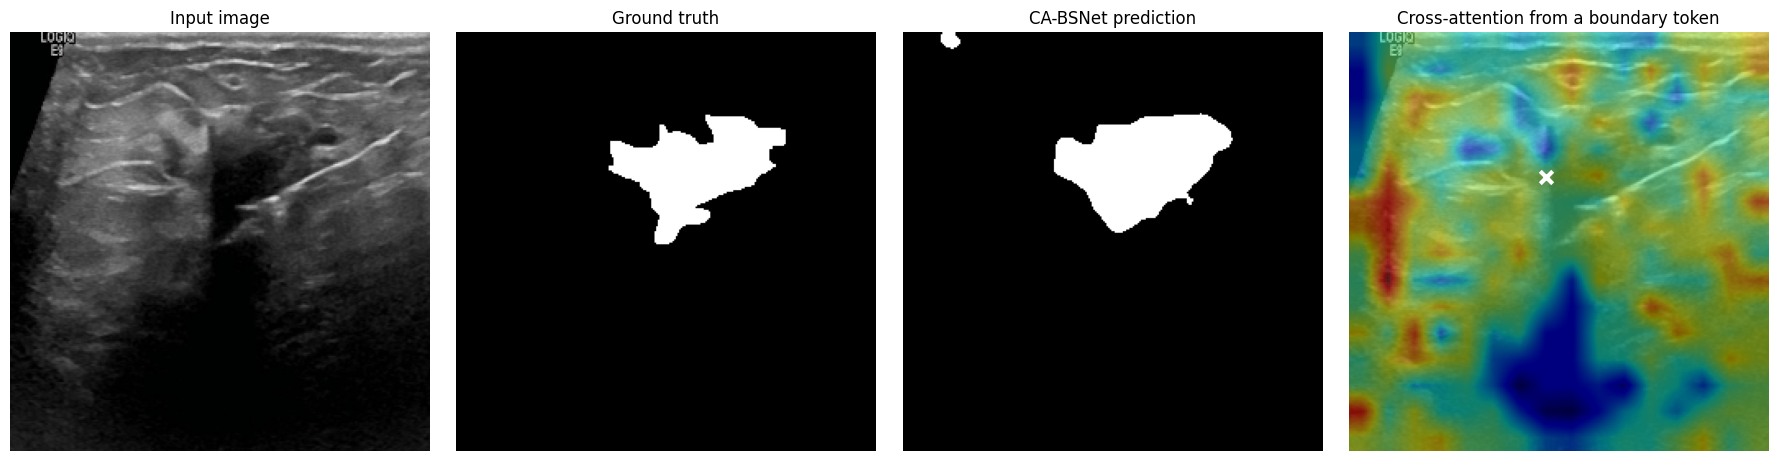

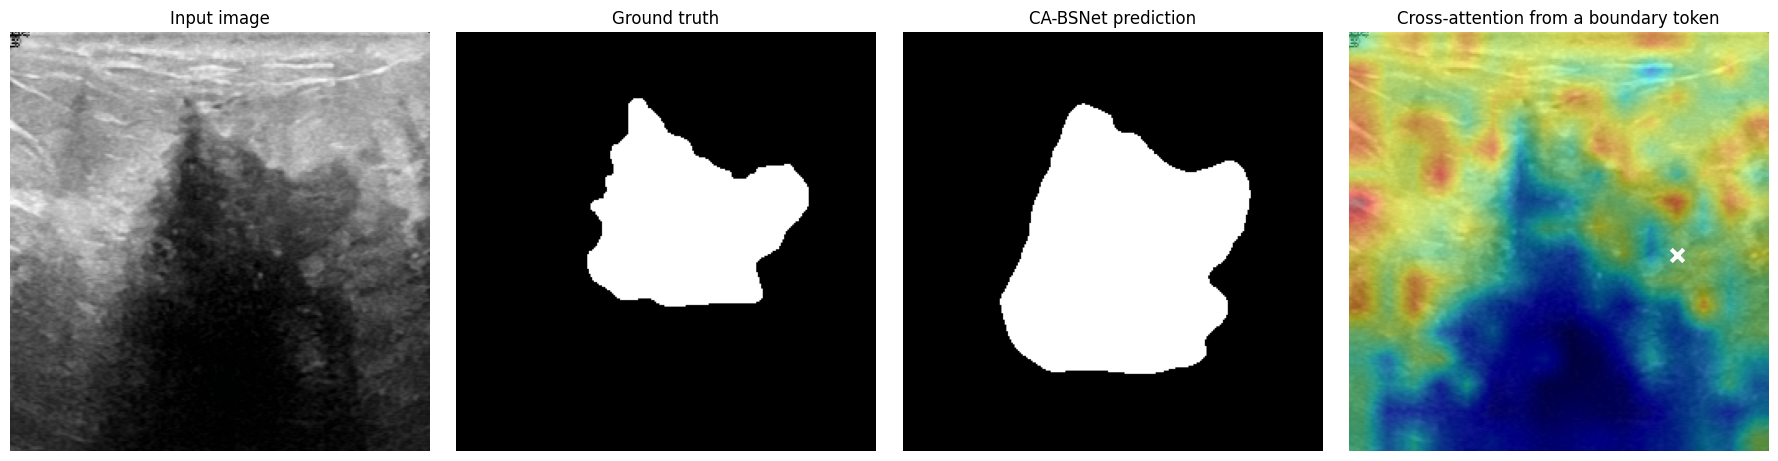

In [ ]:
# CELL 135 - CROSS-ATTENTION VISUALISATION (CA-BSNet, seed 42): for two test images, shows the input, ground truth, prediction
# and where one boundary query token (from AAS) attends in the SSBG boundary features. Illustration of true cross-attention.
# Saves attention_visualization_boundary_idx9.png and ..._idx15.png. Needs cell 126 to have run (for load_ckpt_compat).
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F
from scipy import ndimage

ca_vis_model = load_ckpt_compat(CABSNet().to(device), f'{FINAL_DIR}/tier3_cabsnet/checkpoints/cabsnet_best.pth', device)
ca_vis_model.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def visualize_attention_boundary(model, image_tensor, gt_mask, device):
    model.eval()
    with torch.no_grad():
        x = image_tensor.to(device)
        f_low, f_high = model.backbone(x)
        f_low_r = model.reduce_low(f_low)
        f_high_r = model.reduce_high(f_high)
        f_ssbg_out = model.ssbg(f_low_r)
        f_aas_out = model.aas(f_high_r)
        f_ca_out, attn_weights = model.cross_attn(f_aas_out, f_ssbg_out)
        f_sfh_out = model.sfh(f_ssbg_out, f_ca_out)
        logits = model.decoder(f_sfh_out, x.shape[2:])
        pred_mask = (torch.sigmoid(logits) > 0.5).cpu().numpy()[0, 0]

    attn = attn_weights[0].cpu().numpy()
    mask_small = F.interpolate(torch.tensor(pred_mask[None, None]).float(), size=(16, 16), mode='nearest')[0, 0].numpy()
    eroded = ndimage.binary_erosion(mask_small > 0)
    boundary_positions = np.argwhere((mask_small > 0) & ~eroded)
    if len(boundary_positions) == 0:
        print("Prediction has no boundary at 16x16 - skipping this image"); return None
    query_row, query_col = boundary_positions[len(boundary_positions) // 2]
    query_idx = query_row * 16 + query_col

    attn_row = attn[query_idx].reshape(16, 16)
    attn_upsampled = F.interpolate(torch.tensor(attn_row[None, None]).float(), size=(256, 256), mode='bilinear', align_corners=False)[0, 0].numpy()

    img = image_tensor[0].permute(1, 2, 0).numpy()
    img = (img * std + mean).clip(0, 1)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    axes[0].imshow(img); axes[0].set_title("Input image"); axes[0].axis('off')
    axes[1].imshow(gt_mask, cmap='gray'); axes[1].set_title("Ground truth"); axes[1].axis('off')
    axes[2].imshow(pred_mask, cmap='gray'); axes[2].set_title("CA-BSNet prediction"); axes[2].axis('off')
    axes[3].imshow(img)
    axes[3].imshow(attn_upsampled, cmap='jet', alpha=0.5)
    axes[3].scatter([query_col * 16 + 8], [query_row * 16 + 8], c='white', s=80, marker='x', linewidths=3)
    axes[3].set_title("Cross-attention from a boundary token")
    axes[3].axis('off')
    plt.tight_layout()
    return fig

batch = next(iter(test_loader))
for idx in (9, 15):
    fig = visualize_attention_boundary(ca_vis_model, batch["image"][idx:idx+1], batch["mask"][idx, 0].numpy(), device)
    if fig is not None:
        fig.savefig(f'{FINAL_DIR}/attention_visualization_boundary_idx{idx}.png', dpi=150, bbox_inches='tight')
        plt.show()

del ca_vis_model
torch.cuda.empty_cache()